# CNN Building Blocks: Filters, Stride, Padding, Feature Maps & Pooling Invariance

This notebook walks step-by-step through the core concepts from **Chapter 14 (Deep Computer Vision Using CNNs)**:
1. **Fetching Image Data** from the internet (and Scikit-Learn sample images).
2. **Filters & Stacking Feature Maps:** Sliding vertical and horizontal filters across the image.
3. **Stride & Zero Padding:** Seeing how step size (`stride`) shrinks the output and how `zero padding` protects image boundaries.
4. **Pooling Layer (Max vs. Mean):** Aggregating inputs with **no weights**—comparing Max Pooling (dropping smaller values) vs. Mean Pooling.
5. **Location / Shift Invariance:** Shifting an image by 1 pixel to see why **Max Pooling** keeps the output stable.

In [1]:
import urllib.request
import io
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.datasets import load_sample_image

plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["image.cmap"] = "gray"

## 1. Fetching Image Data from the Internet
We fetch a test image directly from the web (with automatic fallback to Chapter 14's classic `china.jpg` temple image from Scikit-Learn) and convert it to normalized grayscale `[0.0, 1.0]`.

Offline fallback to Chapter 14 sample image (HTTP Error 404: Not Found)
Input Image Shape: (256, 256)


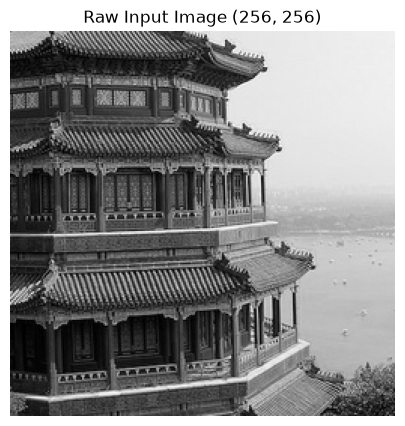

In [2]:
url = "https://raw.githubusercontent.com/scikit-image/scikit-image/main/skimage/data/camera.png"

try:
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, timeout=5) as response:
        img_pil = Image.open(io.BytesIO(response.read())).convert("L").resize((256, 256))
    image = np.asarray(img_pil, dtype=np.float32) / 255.0
    print("Fetched image from the internet successfully!")
except Exception as e:
    print(f"Offline fallback to Chapter 14 sample image ({e})")
    china = load_sample_image("china.jpg")
    # Crop a 256x256 patch and convert to grayscale [0, 1]
    image = china[100:356, 150:406].mean(axis=2).astype(np.float32) / 255.0

print(f"Input Image Shape: {image.shape}")

plt.figure(figsize=(5, 5))
plt.imshow(image, cmap="gray")
plt.title(f"Raw Input Image {image.shape}")
plt.axis("off")
plt.show()

## 2. Convolution Function: Receptive Field, Stride, Padding & Feature Maps

Here is what happens inside a **Convolutional Layer**:
* **Receptive Field:** Each neuron looks only at a small window (e.g., `3 × 3` or `7 × 7` pixels).
* **Stride:** The step size deciding how many pixels the receptive field window moves across the image.
* **Padding (`same` vs `valid`):** Adding `0`s around the boundaries (edges) of the image so the window doesn't run out of pixels at the borders.
* **Feature Map:** Sliding one filter across the whole image produces one 2D Feature Map where all neurons share the exact same weights.

Single Feature Map shape : (256, 256)
Stacked Feature Maps shape: (256, 256, 2)  (Height, Width, # of Filters)


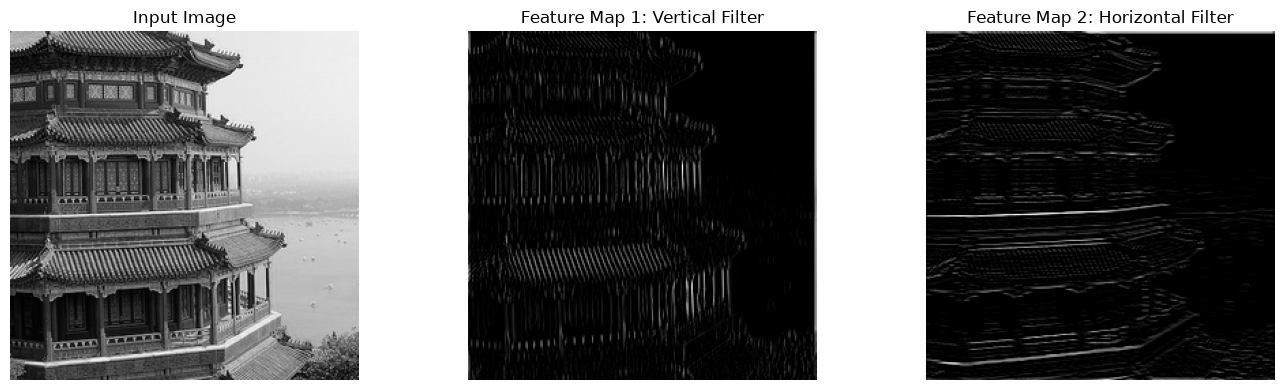

In [3]:
def conv2d(img, kernel, stride=1, padding="same"):
    """Slide a 2D filter (kernel) across the image with given stride and padding."""
    kh, kw = kernel.shape
    if padding == "same":
        pad_h, pad_w = kh // 2, kw // 2
        padded = np.pad(img, ((pad_h, pad_h), (pad_w, pad_w)), mode="constant", constant_values=0)
    else:  # 'valid' (no zero padding)
        padded = img

    H, W = padded.shape
    out_h = (H - kh) // stride + 1
    out_w = (W - kw) // stride + 1
    feature_map = np.zeros((out_h, out_w), dtype=np.float32)

    for i in range(out_h):
        for j in range(out_w):
            # Extract the local receptive field window
            receptive_field = padded[i * stride : i * stride + kh, j * stride : j * stride + kw]
            # Weighted sum using the shared filter weights
            feature_map[i, j] = np.sum(receptive_field * kernel)

    # Apply ReLU activation (keep positive activations)
    return np.maximum(0, feature_map)


# Create two 5x5 filters (like Chapter 14):
# 1. Vertical Line Filter (bright column in the middle)
vertical_filter = np.full((5, 5), -1.0, dtype=np.float32)
vertical_filter[:, 2] = 4.0

# 2. Horizontal Line Filter (bright row in the middle)
horizontal_filter = np.full((5, 5), -1.0, dtype=np.float32)
horizontal_filter[2, :] = 4.0

# Compute each Feature Map and stack them into a 3D stack
fmap_vertical = conv2d(image, vertical_filter, stride=1, padding="same")
fmap_horizontal = conv2d(image, horizontal_filter, stride=1, padding="same")
stacked_feature_maps = np.stack([fmap_vertical, fmap_horizontal], axis=-1)

print(f"Single Feature Map shape : {fmap_vertical.shape}")
print(f"Stacked Feature Maps shape: {stacked_feature_maps.shape}  (Height, Width, # of Filters)")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].imshow(image)
axes[0].set_title("Input Image")
axes[1].imshow(fmap_vertical)
axes[1].set_title("Feature Map 1: Vertical Filter")
axes[2].imshow(fmap_horizontal)
axes[2].set_title("Feature Map 2: Horizontal Filter")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3. Effect of Stride & Padding
* **Padding (`same` vs `valid`):** Without zero padding (`valid`), the edges get cut off and the image shrinks slightly.
* **Stride (`1` vs `2` vs `4`):** Increasing the stride makes the receptive field window take bigger jumps across the image, shrinking the resulting feature map.

Stride=1, Padding='same'  -> shape: (256, 256) (keeps exact image size)
Stride=1, Padding='valid' -> shape: (252, 252) (loses border pixels)
Stride=2, Padding='same'  -> shape: (128, 128) (halves height & width)
Stride=4, Padding='same'  -> shape: (64, 64) (quarters height & width)


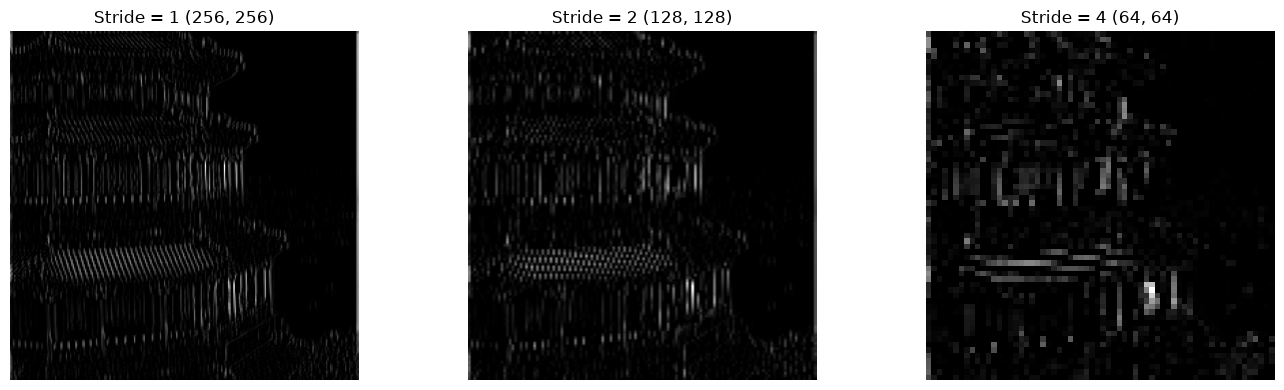

In [4]:
fmap_s1_same = conv2d(image, vertical_filter, stride=1, padding="same")
fmap_s1_valid = conv2d(image, vertical_filter, stride=1, padding="valid")
fmap_s2 = conv2d(image, vertical_filter, stride=2, padding="same")
fmap_s4 = conv2d(image, vertical_filter, stride=4, padding="same")

print(f"Stride=1, Padding='same'  -> shape: {fmap_s1_same.shape} (keeps exact image size)")
print(f"Stride=1, Padding='valid' -> shape: {fmap_s1_valid.shape} (loses border pixels)")
print(f"Stride=2, Padding='same'  -> shape: {fmap_s2.shape} (halves height & width)")
print(f"Stride=4, Padding='same'  -> shape: {fmap_s4.shape} (quarters height & width)")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].imshow(fmap_s1_same)
axes[0].set_title(f"Stride = 1 {fmap_s1_same.shape}")
axes[1].imshow(fmap_s2)
axes[1].set_title(f"Stride = 2 {fmap_s2.shape}")
axes[2].imshow(fmap_s4)
axes[2].set_title(f"Stride = 4 {fmap_s4.shape}")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Pooling Layer: Max Pooling vs. Mean (Average) Pooling
Pooling layers shrink the feature map to reduce computational load and have **no learnable weights**:
* **Max Pooling:** Picks only the **maximum** value inside the receptive field window and **drops all other values** (keeps the strongest feature signals sharp).
* **Mean Pooling:** Averages all values inside the receptive field window (tends to smooth/blur out sharp activations).

Original Feature Map : (256, 256) (65,536 values)
2x2 Max Pooled       : (128, 128) (16,384 values -> 75% dropped!)
2x2 Mean Pooled      : (128, 128)


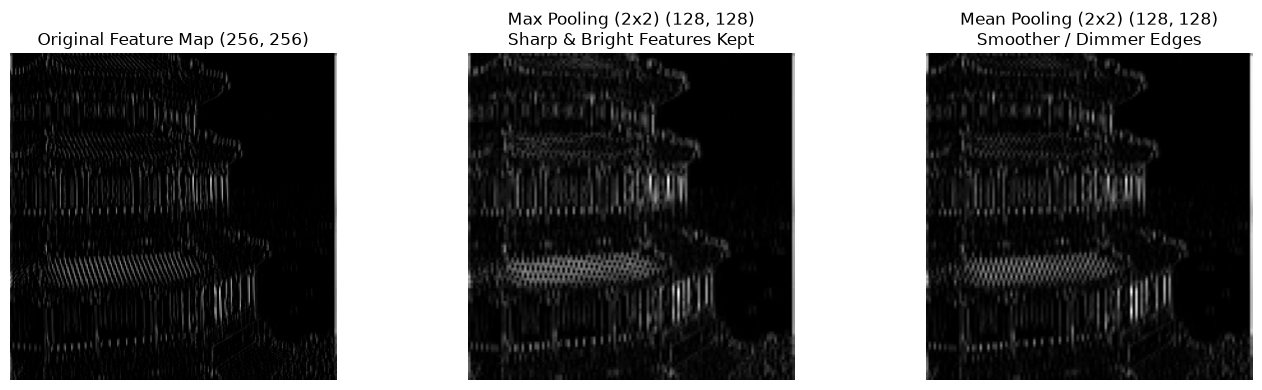

In [5]:
def pool2d(feature_map, pool_size=2, stride=2, mode="max"):
    """Apply Max or Mean pooling with no weights."""
    H, W = feature_map.shape
    out_h = (H - pool_size) // stride + 1
    out_w = (W - pool_size) // stride + 1
    pooled = np.zeros((out_h, out_w), dtype=np.float32)

    for i in range(out_h):
        for j in range(out_w):
            window = feature_map[i * stride : i * stride + pool_size, j * stride : j * stride + pool_size]
            if mode == "max":
                pooled[i, j] = np.max(window)   # Keep max, drop the rest!
            elif mode == "mean":
                pooled[i, j] = np.mean(window)  # Average all inputs in the window
    return pooled


max_pooled = pool2d(fmap_vertical, pool_size=2, stride=2, mode="max")
mean_pooled = pool2d(fmap_vertical, pool_size=2, stride=2, mode="mean")

print(f"Original Feature Map : {fmap_vertical.shape} ({fmap_vertical.size:,} values)")
print(f"2x2 Max Pooled       : {max_pooled.shape} ({max_pooled.size:,} values -> 75% dropped!)")
print(f"2x2 Mean Pooled      : {mean_pooled.shape}")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].imshow(fmap_vertical)
axes[0].set_title(f"Original Feature Map {fmap_vertical.shape}")
axes[1].imshow(max_pooled)
axes[1].set_title(f"Max Pooling (2x2) {max_pooled.shape}\nSharp & Bright Features Kept")
axes[2].imshow(mean_pooled)
axes[2].set_title(f"Mean Pooling (2x2) {mean_pooled.shape}\nSmoother / Dimmer Edges")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 5. How Pooling Gives Shift / Location Invariance
What happens if an object in the image **shifts slightly by 1 pixel** to the right?
* Below, we create a simple image of a bright vertical line, and then **shift it by 1 pixel to the right**.
* Without pooling, the feature maps don't line up at all (`0%` overlap on the line).
* With **Max Pooling**, because both positions still fall inside the same receptive field window, picking the `max` gives the **exact same output** (or preserves high similarity across real images)!

=== 1-Pixel Shift Invariance Demo ===
Difference BEFORE Pooling (Original vs 1px Shifted): 2.5
Difference AFTER 2x2 Max Pooling                  : 0.0 (100% Invariant!)

=== Real Image 1-Pixel Shift Sensitivity (Lower = More Invariant) ===
Unpooled Feature Map Relative Error : 141.31%
Mean Pooled (4x4) Relative Error    : 33.35%
Max Pooled  (4x4) Relative Error    : 26.56%  <-- Most resilient to small shifts!


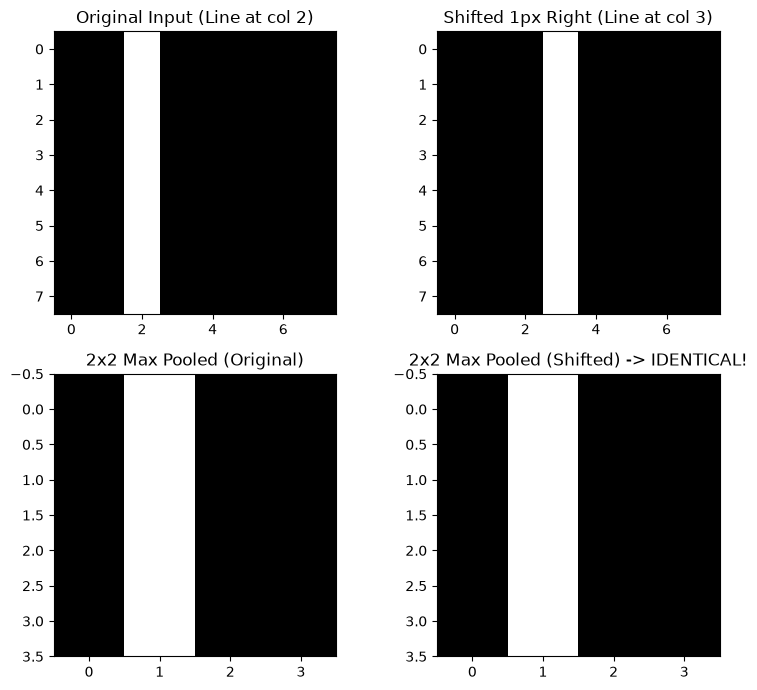

In [6]:
# 1. Toy demonstration on an 8x8 grid (like Figure 14-9 in the book)
toy_original = np.zeros((8, 8), dtype=np.float32)
toy_original[:, 2] = 10.0  # Vertical line at column 2

toy_shifted = np.zeros((8, 8), dtype=np.float32)
toy_shifted[:, 3] = 10.0   # Shifted 1 pixel right to column 3!

max_orig = pool2d(toy_original, pool_size=2, stride=2, mode="max")
max_shift = pool2d(toy_shifted, pool_size=2, stride=2, mode="max")

print("=== 1-Pixel Shift Invariance Demo ===")
print("Difference BEFORE Pooling (Original vs 1px Shifted):", np.abs(toy_original - toy_shifted).mean())
print("Difference AFTER 2x2 Max Pooling                  :", np.abs(max_orig - max_shift).mean(), "(100% Invariant!)")

# 2. Test on our real image shifted by 1 pixel to the right
image_shifted_1px = np.roll(image, shift=1, axis=1)
fmap_orig = conv2d(image, vertical_filter, stride=1, padding="same")
fmap_shift = conv2d(image_shifted_1px, vertical_filter, stride=1, padding="same")

# Normalize each map to compare relative change from a 1-pixel shift
raw_diff = np.mean(np.abs(fmap_orig - fmap_shift)) / (np.mean(fmap_orig) + 1e-8)
max4_orig = pool2d(fmap_orig, pool_size=4, stride=4, mode="max")
max4_shift = pool2d(fmap_shift, pool_size=4, stride=4, mode="max")
max_diff = np.mean(np.abs(max4_orig - max4_shift)) / (np.mean(max4_orig) + 1e-8)

mean4_orig = pool2d(fmap_orig, pool_size=4, stride=4, mode="mean")
mean4_shift = pool2d(fmap_shift, pool_size=4, stride=4, mode="mean")
mean_diff = np.mean(np.abs(mean4_orig - mean4_shift)) / (np.mean(mean4_orig) + 1e-8)

print("\n=== Real Image 1-Pixel Shift Sensitivity (Lower = More Invariant) ===")
print(f"Unpooled Feature Map Relative Error : {raw_diff:.2%}")
print(f"Mean Pooled (4x4) Relative Error    : {mean_diff:.2%}")
print(f"Max Pooled  (4x4) Relative Error    : {max_diff:.2%}  <-- Most resilient to small shifts!")

fig, axes = plt.subplots(2, 2, figsize=(8, 7))
axes[0, 0].imshow(toy_original)
axes[0, 0].set_title("Original Input (Line at col 2)")
axes[0, 1].imshow(toy_shifted)
axes[0, 1].set_title("Shifted 1px Right (Line at col 3)")
axes[1, 0].imshow(max_orig)
axes[1, 0].set_title("2x2 Max Pooled (Original)")
axes[1, 1].imshow(max_shift)
axes[1, 1].set_title("2x2 Max Pooled (Shifted) -> IDENTICAL!")
plt.tight_layout()
plt.show()